# 02 - Model training & tracking
Runs the same code as CI (`python -m heartml.train`). Every candidate is logged to MLflow.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [2]:
import logging, json
import pandas as pd
from IPython.display import Image, display
from heartml import config
from heartml.train import train
logging.basicConfig(level=logging.INFO)

2026/10/20 20:00:12 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Aboli\Documents\MLops assignment\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [3]:
meta = train()

INFO:heartml.data:Clean dataset: 303 rows -> C:\Users\Aboli\Documents\MLops assignment\data\processed\heart_clean.csv


INFO:heartml.train:Tuning logistic_regression over 8 combinations


C:\Users\Aboli\Documents\MLops assignment\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\Aboli\Documents\MLops assignment\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


INFO:heartml.train:logistic_regression: cv_roc_auc=0.905 test_roc_auc=0.969


...

INFO:heartml.train:gradient_boosting: cv_roc_auc=0.884 test_roc_auc=0.960


INFO:heartml.train:Selected logistic_regression (cv ROC-AUC 0.905)


C:\Users\Aboli\Documents\MLops assignment\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Aboli\Documents\MLops assignment\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternativel

              model  cv_roc_auc_mean  cv_accuracy_mean  test_accuracy  test_precision  test_recall  test_roc_auc
logistic_regression           0.9045            0.8471         0.8852          0.8387       0.9286        0.9686
      random_forest           0.8993            0.8304         0.8852          0.8387       0.9286        0.9491
  gradient_boosting           0.8839            0.8180         0.9016          0.8667       0.9286        0.9600


Registered model 'heart-disease-classifier' already exists. Creating a new version of this model...
Created version '2' of model 'heart-disease-classifier'.


In [4]:
pd.read_csv(config.ROOT / 'reports' / 'model_comparison.csv').set_index('model').T

model,logistic_regression,random_forest,gradient_boosting
cv_accuracy_mean,0.8471,0.8304,0.8180
cv_precision_mean,0.8768,0.8436,0.8456
cv_recall_mean,0.7834,0.7826,0.7561
cv_f1_mean,0.8245,0.8069,0.7921
cv_roc_auc_mean,0.9045,0.8993,0.8839
cv_accuracy_std,0.0100,0.0341,0.0364
cv_precision_std,0.0542,0.0598,0.0817
cv_recall_std,0.0459,0.0893,0.0696
cv_f1_std,0.0069,0.0440,0.0350
cv_roc_auc_std,0.0145,0.0248,0.0298


In [5]:
print(json.dumps(meta, indent=2, default=str))

{
  "model_name": "logistic_regression",
  "mlflow_run_id": "7248e4c109824fc9a37861bcad628e2a",
  "best_params": {
    "model__C": 1.0,
    "model__penalty": "l2"
  },
  "metrics": {
    "cv_accuracy_mean": 0.8471,
    "cv_precision_mean": 0.8768,
    "cv_recall_mean": 0.7834,
    "cv_f1_mean": 0.8245,
    "cv_roc_auc_mean": 0.9045,
    "cv_accuracy_std": 0.01,
    "cv_precision_std": 0.0542,
    "cv_recall_std": 0.0459,
    "cv_f1_std": 0.0069,
    "cv_roc_auc_std": 0.0145,
    "test_accuracy": 0.8852,
    "test_precision": 0.8387,
    "test_recall": 0.9286,
    "test_f1": 0.8814,
    "test_roc_auc": 0.9686
  },
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "sex",
    "fbs",
    "exang",
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal"
  ],
  "trained_at": "2026-10-20T14:31:03+00:00",
  "sklearn_version": "1.9.1",
  "n_samples": 303,
  "quick_mode": false
}


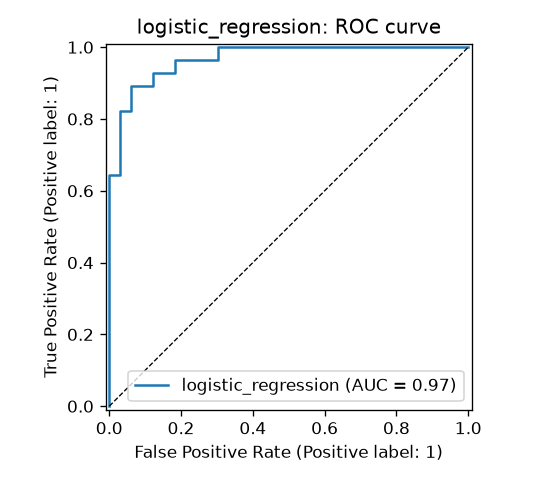

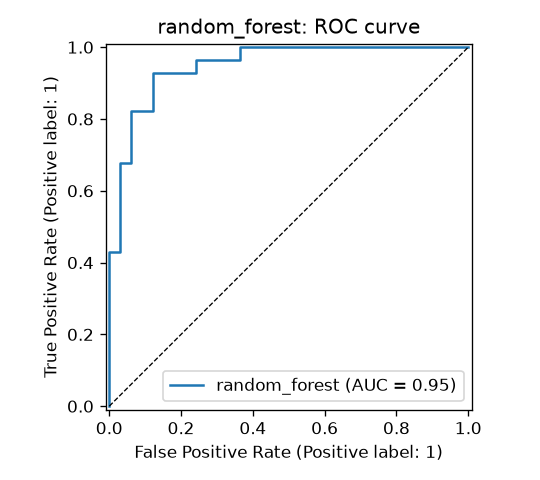

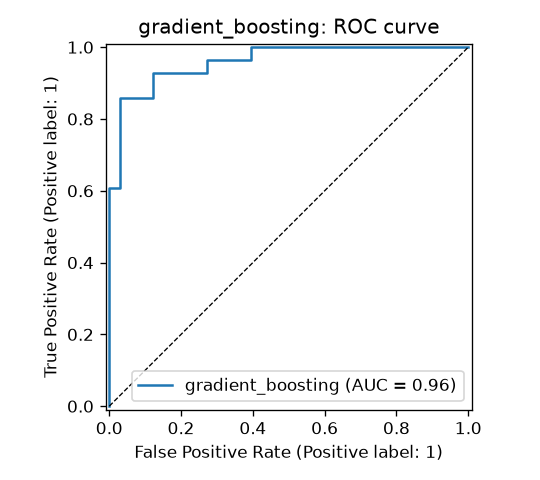

In [6]:
plots = config.ROOT / 'reports' / 'model_plots'
for name in ['logistic_regression', 'random_forest', 'gradient_boosting']:
    display(Image(plots / f'{name}_roc_curve.png'))

Browse all runs with `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root.